In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

TARGET = "Target_local_recurrence"
SEED = 42
TEST_SIZE = 0.25
N_SPLITS = 5
N_REPEATS = 10
C = 0.1
MAX_ITER = 2000

warnings.filterwarnings("ignore", message="Found unknown categories", category=UserWarning)

## 1. Данные

In [2]:
data = pd.read_csv("../w4/analytic_table.csv")
cv_data, test = train_test_split(
    data, test_size=TEST_SIZE, stratify=data[TARGET], random_state=SEED,
)

saved_test_ids = pd.read_csv("../w5/test.csv", usecols=["Patient_ID"])["Patient_ID"]
assert set(test["Patient_ID"]) == set(saved_test_ids)
assert not set(test["Patient_ID"]) & set(cv_data["Patient_ID"])

samples = {
    "Тестовая выборка (отложена)": test,
    "Данные для кросс-валидации": cv_data,
    "Всего": data,
}
pd.DataFrame(
    {
        "Объектов": [len(sample) for sample in samples.values()],
        "С исходом 1": [sample[TARGET].sum() for sample in samples.values()],
    },
    index=samples.keys(),
)

,Объектов,С исходом 1
Тестовая выборка (отложена),35,3
Данные для кросс-валидации,105,9
Всего,140,12


In [3]:
X = cv_data.drop(columns=["Patient_ID", TARGET]).reset_index(drop=True)
y = cv_data[TARGET].reset_index(drop=True)

## 2. Модель

In [4]:
class OutlierAwareScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, median, q3 = np.percentile(X, [25, 50, 75], axis=0)
        iqr = q3 - q1
        self.robust_ = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).any(axis=0)
        self.center_ = np.where(self.robust_, median, X.mean(axis=0))
        scale = np.where(self.robust_, iqr, X.std(axis=0))
        self.scale_ = np.where(scale == 0, 1.0, scale)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.center_) / self.scale_

In [5]:
binary = ["Gender", "Induction_Chemotherapy", "Concurrent_chemotherapy"]
nominal = ["Race", "Tumor_side", "Tumor_subsite", "Smoking_status_at_diagnosis"]
ordinal_categories = {
    "T_category": [1, 2, 3, 4],
    "N_category": ["0", "1", "2a", "2b", "2c", "3"],
    "AJCC_Stage": ["I", "II", "III", "IV"],
    "Pathological_grade": ["I", "I-II", "II", "II-III", "III", "IV", np.nan],
}
ordinal = list(ordinal_categories)
quantitative = [column for column in X.columns if column not in [*binary, *nominal, *ordinal]]

preparation = ColumnTransformer(
    [
        ("quantitative", make_pipeline(SimpleImputer(strategy="median"), OutlierAwareScaler()), quantitative),
        ("ordinal", make_pipeline(
            OrdinalEncoder(categories=list(ordinal_categories.values())),
            SimpleImputer(strategy="median"),
            StandardScaler(),
        ), ordinal),
        ("binary", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(drop="if_binary"),
        ), binary),
        ("nominal", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(drop="first", min_frequency=5, handle_unknown="infrequent_if_exist"),
        ), nominal),
        ("grade_missing", MissingIndicator(features="all"), ["Pathological_grade"]),
    ],
    sparse_threshold=0,
)

model = Pipeline([
    ("prepare", preparation),
    ("classifier", LogisticRegression(C=C, class_weight="balanced", max_iter=MAX_ITER)),
])
rule = DummyClassifier(strategy="most_frequent")

print(f"Логистическая регрессия: C = {C}, классы уравновешены весами")
print(f"Простое правило: всем объектам исход {y.mode()[0]} "
      f"(чаще встречается: {(y == y.mode()[0]).sum()} из {len(y)})")

Логистическая регрессия: C = 0.1, классы уравновешены весами
Простое правило: всем объектам исход 0 (чаще встречается: 96 из 105)


## 3. Кросс-валидация

In [6]:
METRICS = {
    "Accuracy": lambda y_true, y_pred, score: accuracy_score(y_true, y_pred),
    "Precision": lambda y_true, y_pred, score: precision_score(y_true, y_pred, zero_division=0),
    "Recall": lambda y_true, y_pred, score: recall_score(y_true, y_pred),
    "Specificity": lambda y_true, y_pred, score: recall_score(y_true, y_pred, pos_label=0),
    "F1": lambda y_true, y_pred, score: f1_score(y_true, y_pred, zero_division=0),
    "Balanced Accuracy": lambda y_true, y_pred, score: balanced_accuracy_score(y_true, y_pred),
    "ROC AUC": lambda y_true, y_pred, score: roc_auc_score(y_true, score),
}
estimators = {"Логистическая регрессия": model, "Простое правило": rule}

cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
rows = []
for split, (train_index, test_index) in enumerate(cv.split(X, y)):
    assert len(test_index) == len(y) // N_SPLITS
    X_fit, y_fit = X.iloc[train_index], y.iloc[train_index]
    X_check, y_check = X.iloc[test_index], y.iloc[test_index]
    for name, estimator in estimators.items():
        fitted = clone(estimator).fit(X_fit, y_fit)
        predicted = fitted.predict(X_check)
        score = fitted.predict_proba(X_check)[:, 1]
        row = {
            "Модель": name,
            "Повтор": split // N_SPLITS + 1,
            "Блок": split % N_SPLITS + 1,
            "Объектов в блоке": len(y_check),
            "С исходом 1": int(y_check.sum()),
            "Предсказано исходов 1": int(predicted.sum()),
        }
        if name == "Логистическая регрессия":
            row["Признаков с медианой и IQR"] = int(
                fitted["prepare"].named_transformers_["quantitative"][-1].robust_.sum()
            )
        rows.append(row | {metric: f(y_check, predicted, score) for metric, f in METRICS.items()})

folds = pd.DataFrame(rows)
model_folds = folds[folds["Модель"] == "Логистическая регрессия"]
rule_folds = folds[folds["Модель"] == "Простое правило"]

print(f"Повторов: {N_REPEATS}, блоков в каждом: {N_SPLITS}, всего оценок: {len(model_folds)}")
print(f"Объектов в оцениваемом блоке: {model_folds['Объектов в блоке'].iloc[0]}, "
      f"с исходом 1: {model_folds['С исходом 1'].min()}-{model_folds['С исходом 1'].max()}")
n_robust = model_folds["Признаков с медианой и IQR"].astype(int)
print(f"Количественных признаков, нормализованных по медиане и IQR обучающих блоков: "
      f"{n_robust.min()}-{n_robust.max()} из {len(quantitative)}")
print(f"Блоков, где модель не предсказала ни одного исхода 1: {(model_folds['Предсказано исходов 1'] == 0).sum()}")

Повторов: 10, блоков в каждом: 5, всего оценок: 50
Объектов в оцениваемом блоке: 21, с исходом 1: 1-2
Количественных признаков, нормализованных по медиане и IQR обучающих блоков: 14-17 из 20
Блоков, где модель не предсказала ни одного исхода 1: 0


## 4. Метрики

In [7]:
metric_names = list(METRICS)
summary = pd.DataFrame({
    "Логистическая регрессия": model_folds[metric_names].mean(),
    "Простое правило «всегда 0»": rule_folds[metric_names].mean(),
})
summary["Разность"] = summary.iloc[:, 0] - summary.iloc[:, 1]
summary.round(3)

,Логистическая регрессия,Простое правило «всегда 0»,Разность
Accuracy,0.776,0.914,-0.138
Precision,0.148,0.000,0.148
Recall,0.300,0.000,0.300
Specificity,0.819,1.000,-0.181
F1,0.185,0.000,0.185
Balanced Accuracy,0.559,0.500,0.059
ROC AUC,0.647,0.500,0.147


## 5. Разброс метрик

In [8]:
spread = model_folds[metric_names].agg(["mean", "std", "min", "max"]).T
spread["Размах"] = spread["max"] - spread["min"]
repeat_means = model_folds.groupby("Повтор")[metric_names].mean()
spread["Среднее повтора: min"] = repeat_means.min()
spread["Среднее повтора: max"] = repeat_means.max()
spread.round(3)

,mean,std,min,max,Размах,Среднее повтора: min,Среднее повтора: max
Accuracy,0.776,0.077,0.619,0.952,0.333,0.724,0.819
Precision,0.148,0.201,0.000,1.000,1.000,0.084,0.307
Recall,0.300,0.364,0.000,1.000,1.000,0.200,0.400
Specificity,0.819,0.078,0.632,1.000,0.368,0.759,0.866
F1,0.185,0.217,0.000,0.667,0.667,0.130,0.270
Balanced Accuracy,0.559,0.187,0.342,0.921,0.579,0.501,0.606
ROC AUC,0.647,0.173,0.289,0.947,0.658,0.565,0.681


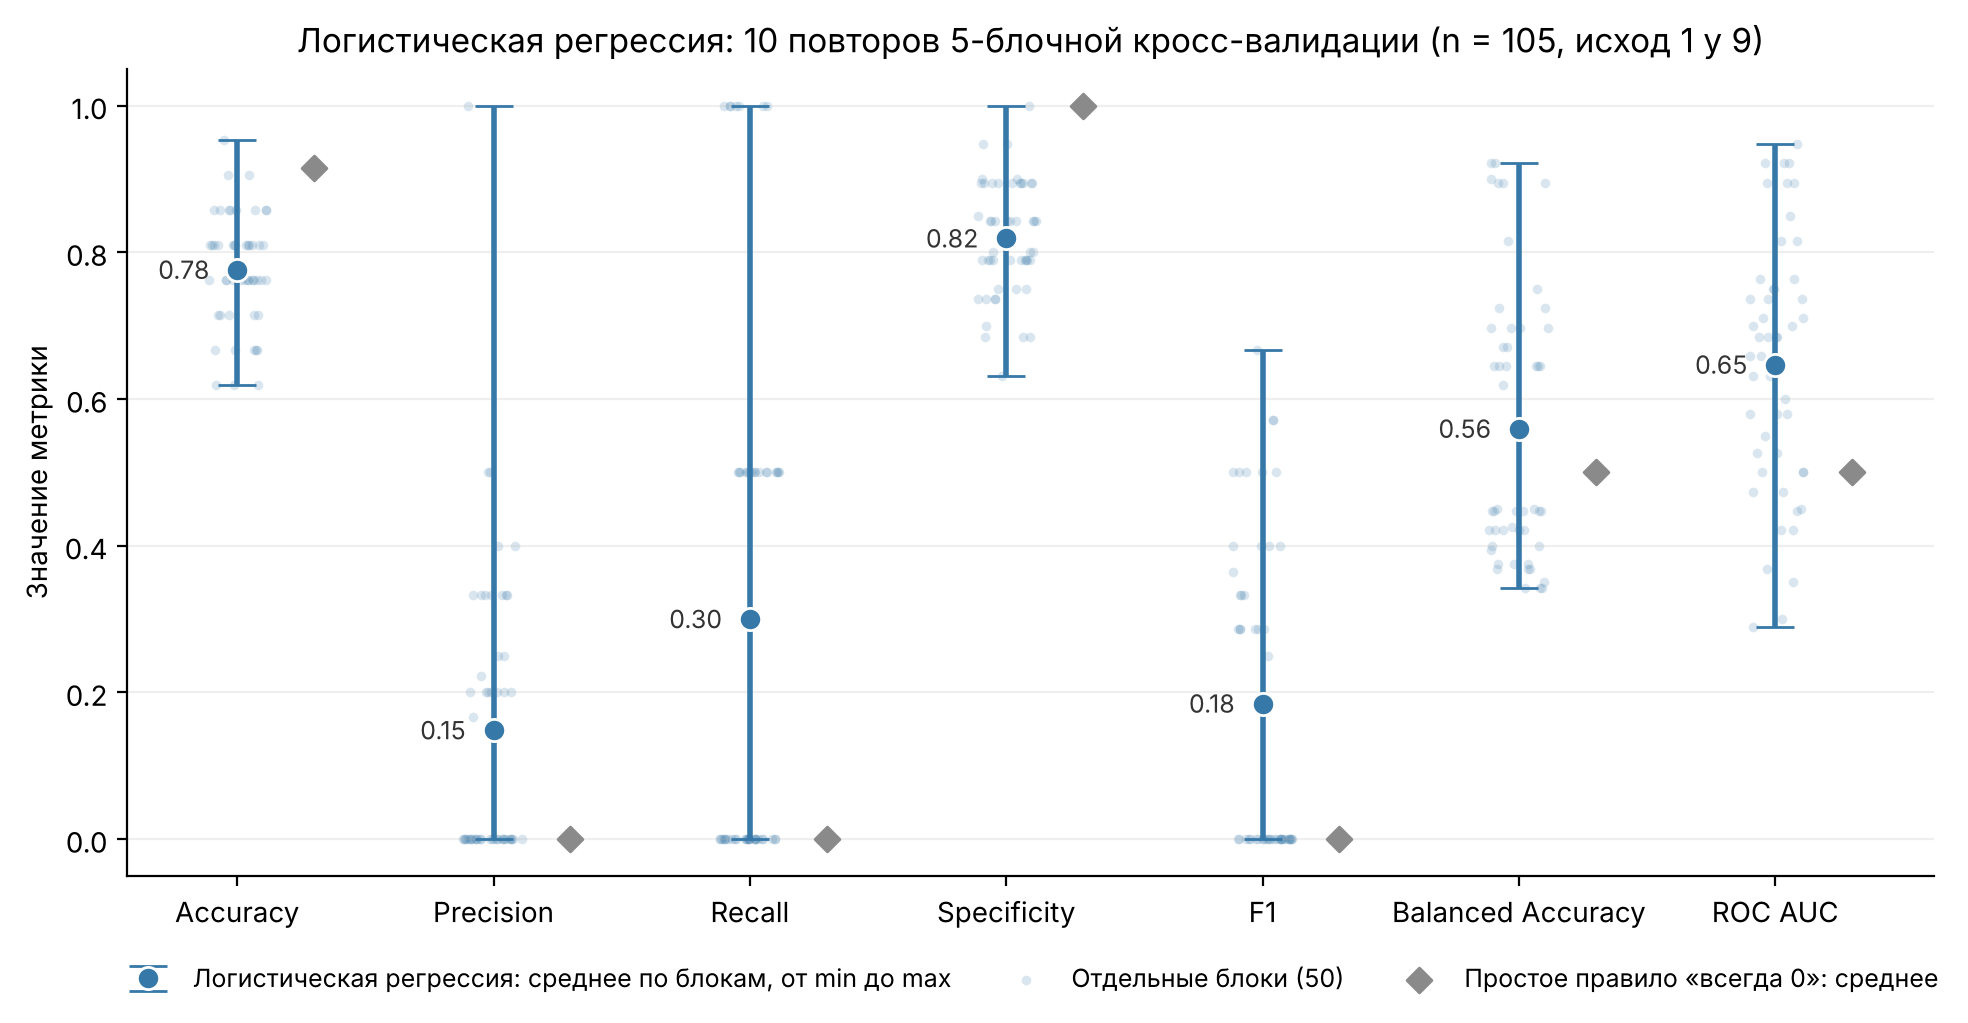

In [9]:
positions = np.arange(len(metric_names))
mean = spread["mean"]
rng = np.random.default_rng(SEED)

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for position, metric in zip(positions, metric_names):
    values = model_folds[metric].to_numpy()
    jitter = rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(position + jitter, values, s=12, color="#3678A8", alpha=0.18, linewidth=0,
               label=f"Отдельные блоки ({len(values)})" if position == 0 else None)
ax.errorbar(positions, mean, yerr=[mean - spread["min"], spread["max"] - mean],
            fmt="o", markersize=8, color="#3678A8", ecolor="#3678A8", elinewidth=2, capsize=7,
            markeredgecolor="white", zorder=3,
            label="Логистическая регрессия: среднее по блокам, от min до max")
ax.scatter(positions + 0.3, summary["Простое правило «всегда 0»"], marker="D", s=40,
           color="#8A8A8A", zorder=3, label="Простое правило «всегда 0»: среднее")
for position, value in zip(positions, mean):
    ax.annotate(f"{value:.2f}", (position, value), xytext=(-10, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9, color="#333333")

ax.set_title(f"Логистическая регрессия: {N_REPEATS} повторов {N_SPLITS}-блочной кросс-валидации "
             f"(n = {len(y)}, исход 1 у {y.sum()})")
ax.set_xticks(positions, metric_names)
ax.set_ylabel("Значение метрики")
ax.set_ylim(-0.05, 1.05)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
order = sorted(range(len(labels)), key=lambda i: ("Логистическая" not in labels[i], "Отдельные" not in labels[i]))
ax.legend([handles[i] for i in order], [labels[i] for i in order], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
plt.show()

## Выводы

Опаснее ложноотрицательный ответ: пропущенный локальный рецидив откладывает повторное лечение, а ложная тревога ведёт лишь к дополнительному обследованию.

Простое правило «всегда нет рецидива» выглядит лучше модели по Accuracy (0,914 против 0,776) и Specificity (1,000 против 0,819) и почти не уступает ей по Balanced Accuracy (0,500 против 0,559). По Recall, Precision, F1 и ROC AUC правило бесполезно: 0, 0, 0 и 0,500 против 0,300, 0,148, 0,185 и 0,647 у модели.

Метрики неустойчивы. В каждом оцениваемом блоке 21 пациент и только 1–2 рецидива, поэтому один пациент меняет Recall на 0,5–1. По 50 блокам Recall и Precision принимают значения от 0 до 1, ROC AUC — от 0,289 до 0,947, Balanced Accuracy — от 0,342 до 0,921. Различаются даже средние отдельных повторов: Recall от 0,200 до 0,400, ROC AUC от 0,565 до 0,681. Accuracy и Specificity меняются меньше (размах 0,333 и 0,368).

Главная метрика — Recall. Она прямо измеряет долю найденных рецидивов, то есть опасную ошибку, и отделяет модель от правила (0,300 против 0). Recall оцениваем средним по всем повторам и приводим вместе со Specificity, иначе высокий Recall достигается прогнозом «рецидив» для всех пациентов.